# 02 - Q-table exploration lab

This notebook is designed to compare Q-learning configurations on `FrozenLake-v1`.

You can tune:

- `epsilon`: fixed, linear decay, exponential decay, sinusoidal exploration
- `alpha`: fixed or scheduled learning rate
- `gamma`: fixed or scheduled discount factor
- reward policy: default, step penalty, hole penalty, goal bonus
- environment: slippery or deterministic, map size, custom map
- number of training episodes and evaluation episodes


In [2]:
from __future__ import annotations

from dataclasses import dataclass, field
from pathlib import Path
import sys

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.pretty_printer import PrettyPrinter

In [3]:
observation_labels = ["Position"]
observation_units = [""]
observation_descriptions = ["Current position in the FrozenLake grid"]
action_labels = {
    0: "Move left",
    1: "Move down",
    2: "Move right",
    3: "Move up",
}

printer = PrettyPrinter(
    observation_labels=observation_labels,
    observation_units=observation_units,
    observation_descriptions=observation_descriptions,
    action_labels=action_labels,
)

## Explore the environment

Start with `is_slippery=True` because it is the more realistic/stochastic version. Set it to `False` to compare against the easier deterministic lake.

In [4]:
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=True)
printer.env(env)
printer.action_probs(env=env, observation=0)


████████████████████████████████████████████████████████████████████████████████████████
ENVIRONNEMENT : FrozenLake-v1
████████████████████████████████████████████████████████████████████████████████████████
Type Python          : TimeLimit
Espace d'observation : Discrete(16)
Espace d'action      : Discrete(4)
Identifiant          : FrozenLake-v1
Étapes maximales     : 100

════════════════════════════════════════════════════════════════════════════════════════
ESPACE D'OBSERVATION
════════════════════════════════════════════════════════════════════════════════════════
Classe : Discrete
Forme  : ()
Type   : int64
Objet  : Discrete(16)

L'affichage détaillé des bornes est prévu principalement pour les espaces Box.

════════════════════════════════════════════════════════════════════════════════════════
ESPACE D'ACTION
════════════════════════════════════════════════════════════════════════════════════════
Classe : Discrete
Forme  : ()
Type   : int64
Objet  : Discrete(4)

Valeur    Sign

## Parameter schedules

A schedule receives the current episode and total number of episodes, then returns the value to use. This lets `epsilon`, `alpha`, and `gamma` change during training.

In [5]:
class Schedule:
    def __call__(self, episode: int, total_episodes: int) -> float:
        raise NotImplementedError


@dataclass(frozen=True)
class ConstantSchedule(Schedule):
    value: float

    def __call__(self, episode: int, total_episodes: int) -> float:
        return self.value


@dataclass(frozen=True)
class LinearDecaySchedule(Schedule):
    start: float
    end: float
    decay_fraction: float = 1.0

    def __call__(self, episode: int, total_episodes: int) -> float:
        decay_episodes = max(1, int(total_episodes * self.decay_fraction))
        progress = min(episode / decay_episodes, 1.0)
        return self.start + progress * (self.end - self.start)


@dataclass(frozen=True)
class ExponentialDecaySchedule(Schedule):
    start: float
    end: float
    decay_rate: float

    def __call__(self, episode: int, total_episodes: int) -> float:
        value = self.end + (self.start - self.end) * np.exp(-self.decay_rate * episode)
        return float(max(self.end, value))


@dataclass(frozen=True)
class LogarithmicDecaySchedule(Schedule):
    start: float
    end: float
    curve: float = 9.0

    def __call__(self, episode: int, total_episodes: int) -> float:
        progress = episode / max(1, total_episodes - 1)
        scaled = np.log1p(self.curve * progress) / np.log1p(self.curve)
        return float(self.start + scaled * (self.end - self.start))


@dataclass(frozen=True)
class RandomUniformSchedule(Schedule):
    low: float
    high: float
    seed: int = 42

    def __call__(self, episode: int, total_episodes: int) -> float:
        rng = np.random.default_rng(self.seed + episode)
        return float(rng.uniform(self.low, self.high))


@dataclass(frozen=True)
class SinusoidalSchedule(Schedule):
    low: float
    high: float
    periods: float = 4.0

    def __call__(self, episode: int, total_episodes: int) -> float:
        progress = episode / max(1, total_episodes - 1)
        wave = 0.5 + 0.5 * np.sin(2 * np.pi * self.periods * progress)
        return float(self.low + wave * (self.high - self.low))


def as_schedule(value: float | Schedule) -> Schedule:
    if isinstance(value, Schedule):
        return value
    return ConstantSchedule(float(value))

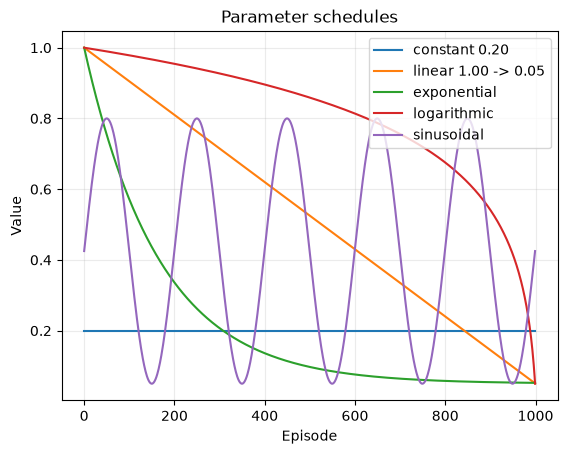

In [19]:
def plot_schedules(schedules: dict[str, Schedule], episodes: int = 1_000) -> None:
    xs = np.arange(episodes)
    for name, schedule in schedules.items():
        ys = [schedule(int(episode), episodes) for episode in xs]
        plt.plot(xs, ys, label=name)

    plt.title("Parameter schedules")
    plt.xlabel("Episode")
    plt.ylabel("Value")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()


plot_schedules({
    "constant 0.20": ConstantSchedule(0.20),
    "linear 1.00 -> 0.05": LinearDecaySchedule(1.0, 0.05),
    "exponential": ExponentialDecaySchedule(1.0, 0.05, decay_rate=0.006),
    "logarithmic": LogarithmicDecaySchedule(1.0, 0.05, curve=-.99),
    # "random per episode": RandomUniformSchedule(0.05, 0.80, seed=7),
    "sinusoidal": SinusoidalSchedule(0.05, 0.80, periods=5),
})

## Reward policies

FrozenLake normally gives `1` only on the goal and `0` everywhere else. That sparse reward can be hard to learn from. These policies let you test reward shaping.

In [21]:
@dataclass(frozen=True)
class RewardPolicy:
    step_penalty: float = 0.0
    hole_penalty: float = 0.0
    goal_bonus: float = 0.0

    def __call__(self, env: gym.Env, state: int, reward: float, terminated: bool) -> float:
        desc = env.unwrapped.desc.astype(str).ravel()
        tile = desc[state]
        shaped_reward = reward + self.step_penalty

        if terminated and tile == "H":
            shaped_reward += self.hole_penalty
        if terminated and tile == "G":
            shaped_reward += self.goal_bonus

        return shaped_reward


class RewardPolicyWrapper(gym.Wrapper):
    def __init__(self, env: gym.Env, reward_policy: RewardPolicy):
        super().__init__(env)
        self.reward_policy = reward_policy

    def step(self, action: int):
        state, reward, terminated, truncated, info = self.env.step(action)
        shaped_reward = self.reward_policy(self.env, state, reward, terminated)
        info = {**info, "base_reward": reward, "shaped_reward": shaped_reward}
        return state, shaped_reward, terminated, truncated, info


DEFAULT_REWARD = RewardPolicy()
STEP_PENALTY_REWARD = RewardPolicy(step_penalty=-0.01)
HOLE_PENALTY_REWARD = RewardPolicy(hole_penalty=-1.0)
SHAPED_REWARD = RewardPolicy(step_penalty=-0.01, hole_penalty=-1.0, goal_bonus=1.0)

## Reusable Q-learning implementation

In [22]:
@dataclass(frozen=True)
class QLearningConfig:
    name: str
    episodes: int = 5_000
    max_steps_per_episode: int = 100
    alpha: float | Schedule = field(default_factory=lambda: ConstantSchedule(0.10))
    gamma: float | Schedule = field(default_factory=lambda: ConstantSchedule(0.95))
    epsilon: float | Schedule = field(default_factory=lambda: LinearDecaySchedule(1.0, 0.05))
    is_slippery: bool = True
    map_name: str = "4x4"
    desc: list[str] | None = None
    reward_policy: RewardPolicy = field(default_factory=RewardPolicy)
    seed: int = 42


@dataclass
class TrainingResult:
    config: QLearningConfig
    q_table: np.ndarray
    episode_rewards: np.ndarray
    episode_successes: np.ndarray
    episode_lengths: np.ndarray
    epsilon_values: np.ndarray
    alpha_values: np.ndarray
    gamma_values: np.ndarray
    evaluation_success_rate: float | None = None
    evaluation_average_reward: float | None = None


class QLearningAgent:
    def __init__(self, observation_count: int, action_count: int, rng: np.random.Generator):
        self.q_table = np.zeros((observation_count, action_count), dtype=float)
        self.rng = rng

    def choose_action(self, env: gym.Env, state: int, epsilon: float) -> int:
        if self.rng.random() < epsilon:
            return int(env.action_space.sample())
        return self.greedy_action(state)

    def greedy_action(self, state: int) -> int:
        best_actions = np.flatnonzero(self.q_table[state] == self.q_table[state].max())
        return int(self.rng.choice(best_actions))

    def update(self, previous_state: int, action: int, state: int, reward: float, alpha: float, gamma: float) -> None:
        old_value = self.q_table[previous_state, action]
        target = reward + gamma * self.q_table[state].max()
        self.q_table[previous_state, action] = old_value + alpha * (target - old_value)


def make_frozen_lake_env(config: QLearningConfig, render_mode: str | None = None) -> gym.Env:
    kwargs = {
        "is_slippery": config.is_slippery,
        "render_mode": render_mode,
    }
    if config.desc is None:
        kwargs["map_name"] = config.map_name
    else:
        kwargs["desc"] = config.desc

    env = gym.make("FrozenLake-v1", **kwargs)
    if config.reward_policy != DEFAULT_REWARD:
        env = RewardPolicyWrapper(env, config.reward_policy)
    return env


def train_q_learning(config: QLearningConfig) -> TrainingResult:
    env = make_frozen_lake_env(config)
    env.action_space.seed(config.seed)
    rng = np.random.default_rng(config.seed)
    agent = QLearningAgent(env.observation_space.n, env.action_space.n, rng)

    epsilon_schedule = as_schedule(config.epsilon)
    alpha_schedule = as_schedule(config.alpha)
    gamma_schedule = as_schedule(config.gamma)

    episode_rewards = np.zeros(config.episodes)
    episode_successes = np.zeros(config.episodes, dtype=bool)
    episode_lengths = np.zeros(config.episodes, dtype=int)
    epsilon_values = np.zeros(config.episodes)
    alpha_values = np.zeros(config.episodes)
    gamma_values = np.zeros(config.episodes)

    for episode in range(config.episodes):
        state, _ = env.reset(seed=config.seed + episode)
        epsilon = epsilon_schedule(episode, config.episodes)
        alpha = alpha_schedule(episode, config.episodes)
        gamma = gamma_schedule(episode, config.episodes)
        total_reward = 0.0

        for step in range(config.max_steps_per_episode):
            action = agent.choose_action(env, state, epsilon)
            previous_state = state
            state, reward, terminated, truncated, info = env.step(action)
            agent.update(previous_state, action, state, reward, alpha, gamma)
            total_reward += reward

            if terminated or truncated:
                break

        desc = env.unwrapped.desc.astype(str).ravel()
        episode_rewards[episode] = total_reward
        episode_successes[episode] = desc[state] == "G"
        episode_lengths[episode] = step + 1
        epsilon_values[episode] = epsilon
        alpha_values[episode] = alpha
        gamma_values[episode] = gamma

    env.close()
    return TrainingResult(
        config=config,
        q_table=agent.q_table,
        episode_rewards=episode_rewards,
        episode_successes=episode_successes,
        episode_lengths=episode_lengths,
        epsilon_values=epsilon_values,
        alpha_values=alpha_values,
        gamma_values=gamma_values,
    )

In [23]:
def evaluate_q_table(result: TrainingResult, episodes: int = 500, seed: int = 10_000) -> TrainingResult:
    env = make_frozen_lake_env(result.config)
    rng = np.random.default_rng(seed)
    rewards = np.zeros(episodes)
    successes = np.zeros(episodes, dtype=bool)

    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        total_reward = 0.0

        for _ in range(result.config.max_steps_per_episode):
            best_actions = np.flatnonzero(result.q_table[state] == result.q_table[state].max())
            action = int(rng.choice(best_actions))
            state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward

            if terminated or truncated:
                break

        desc = env.unwrapped.desc.astype(str).ravel()
        rewards[episode] = total_reward
        successes[episode] = desc[state] == "G"

    env.close()
    result.evaluation_success_rate = float(successes.mean())
    result.evaluation_average_reward = float(rewards.mean())
    return result


def run_experiments(configs: list[QLearningConfig], evaluation_episodes: int = 500) -> list[TrainingResult]:
    results = []
    for config in configs:
        print(f"Training {config.name}...")
        result = train_q_learning(config)
        result = evaluate_q_table(result, episodes=evaluation_episodes)
        results.append(result)
    return results

## Visualization helpers

In [24]:
ACTION_ARROWS = np.array(["L", "D", "R", "U"])


def rolling_mean(values: np.ndarray, window: int = 100) -> np.ndarray:
    if len(values) < window:
        return values.astype(float)
    kernel = np.ones(window) / window
    return np.convolve(values, kernel, mode="valid")


def summarize_results(results: list[TrainingResult]) -> None:
    rows = []
    for result in results:
        train_success_last_500 = result.episode_successes[-500:].mean()
        rows.append((
            result.config.name,
            result.config.is_slippery,
            train_success_last_500,
            result.evaluation_success_rate,
            result.evaluation_average_reward,
        ))

    print(f"{'experiment':35} {'slippery':9} {'train@500':>10} {'eval':>10} {'eval reward':>12}")
    print("-" * 82)
    for name, slippery, train_success, eval_success, eval_reward in rows:
        print(f"{name:35} {str(slippery):9} {train_success:10.3f} {eval_success:10.3f} {eval_reward:12.3f}")


def plot_learning_curves(results: list[TrainingResult], window: int = 100, separate_overlaps: bool = True) -> None:
    plt.figure(figsize=(12, 5))
    line_styles = ["-", "--", "-.", ":"]
    marker_styles = ["o", "s", "^", "D"]

    for index, result in enumerate(results):
        curve = rolling_mean(result.episode_successes.astype(float), window=window)
        y_offset = index * 0.006 if separate_overlaps else 0.0
        plotted_curve = np.clip(curve + y_offset, 0.0, 1.0)
        label = result.config.name
        if separate_overlaps:
            label = f"{label} (+{y_offset:.3f} visual offset)"

        plt.plot(
            plotted_curve,
            label=label,
            linestyle=line_styles[index % len(line_styles)],
            marker=marker_styles[index % len(marker_styles)],
            markevery=max(1, len(plotted_curve) // 12),
            linewidth=2,
            alpha=0.85,
        )
        plt.text(len(plotted_curve) - 1, plotted_curve[-1], str(index + 1), va="center", fontsize=10)

    plt.title(f"Rolling success rate, window={window}")
    plt.xlabel("Episode")
    plt.ylabel("Success rate")
    plt.ylim(-0.05, 1.08)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()


def diagnose_results(results: list[TrainingResult]) -> None:
    for result in results:
        print(result.config.name)
        print(f"  is_slippery: {result.config.is_slippery}")
        print(f"  alpha first/mid/last: {result.alpha_values[0]:.3f}, {result.alpha_values[len(result.alpha_values) // 2]:.3f}, {result.alpha_values[-1]:.3f}")
        print(f"  gamma first/mid/last: {result.gamma_values[0]:.3f}, {result.gamma_values[len(result.gamma_values) // 2]:.3f}, {result.gamma_values[-1]:.3f}")
        print(f"  epsilon first/mid/last: {result.epsilon_values[0]:.3f}, {result.epsilon_values[len(result.epsilon_values) // 2]:.3f}, {result.epsilon_values[-1]:.3f}")

    print("\nPairwise equality checks:")
    for left_index in range(len(results)):
        for right_index in range(left_index + 1, len(results)):
            left = results[left_index]
            right = results[right_index]
            same_successes = np.array_equal(left.episode_successes, right.episode_successes)
            same_q_table = np.allclose(left.q_table, right.q_table)
            print(f"  {left.config.name} vs {right.config.name}: same successes={same_successes}, same q_table={same_q_table}")


def plot_parameter_history(result: TrainingResult) -> None:
    plt.figure(figsize=(12, 4))
    plt.plot(result.epsilon_values, label="epsilon")
    plt.plot(result.alpha_values, label="alpha")
    plt.plot(result.gamma_values, label="gamma")
    plt.title(result.config.name)
    plt.xlabel("Episode")
    plt.ylabel("Value")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()


def show_policy(result: TrainingResult) -> None:
    env = make_frozen_lake_env(result.config)
    desc = env.unwrapped.desc.astype(str)
    flat_desc = desc.ravel()
    policy = []

    for state, tile in enumerate(flat_desc):
        if tile in {"H", "G"}:
            policy.append(tile)
            continue

        values = result.q_table[state]
        best_actions = np.flatnonzero(values == values.max())
        if np.allclose(values, 0.0) or len(best_actions) > 1:
            policy.append("?")
        else:
            policy.append(ACTION_ARROWS[best_actions[0]])

    policy = np.array(policy).reshape(desc.shape)

    for row_index, row in enumerate(desc):
        cells = []
        for column_index, tile in enumerate(row):
            cells.append(policy[row_index, column_index])
        print("  ".join(cells))

    print("Legend: L=left, D=down, R=right, U=up, ?=no clear learned preference, H=hole, G=goal")
    env.close()


def plot_q_table(result: TrainingResult) -> None:
    env = make_frozen_lake_env(result.config)
    desc = env.unwrapped.desc.astype(str).ravel()
    fig, ax = plt.subplots(figsize=(8, 5))
    image = ax.imshow(result.q_table, aspect="auto", cmap="viridis")
    fig.colorbar(image, ax=ax, label="Q value")

    hole_states = np.flatnonzero(desc == "H")
    for state in hole_states:
        ax.axhline(state - 0.5, color="red", linewidth=1, alpha=0.35)
        ax.axhline(state + 0.5, color="red", linewidth=1, alpha=0.35)
        for action in range(result.q_table.shape[1]):
            ax.text(action, state, "X", color="red", ha="center", va="center", fontsize=12, fontweight="bold")

    y_labels = [f"{state} ({tile})" if tile in {"H", "G"} else str(state) for state, tile in enumerate(desc)]
    ax.set_title(result.config.name)
    ax.set_xlabel("Action")
    ax.set_ylabel("State")
    ax.set_xticks(range(result.q_table.shape[1]), [action_labels[i] for i in range(result.q_table.shape[1])], rotation=30, ha="right")
    ax.set_yticks(range(len(y_labels)), y_labels)
    ax.text(0.99, 0.01, "red X = hole state", transform=ax.transAxes, color="red", ha="right", va="bottom", fontweight="bold")
    env.close()
    plt.show()

## Experiment set 1: exploration schedules

Compare fixed exploration, normal decay, fast decay, logarithmic decay, random per-episode exploration, and sinusoidal exploration.

The shared base values are intentionally conservative:

- `alpha = 0.10`: each Q update moves only 10% toward the new target. On slippery FrozenLake, transitions are stochastic, so a smaller learning rate avoids overreacting to one lucky or unlucky step.
- `gamma = 0.95`: future reward matters because the goal is several steps away. It is below `1.0` so shorter/safer paths are still preferred and value estimates stay numerically stable.

These are not magic constants. They are stable defaults for comparing `epsilon` strategies before changing multiple things at once.

Training epsilon fixed 0.10...
Training epsilon fixed 0.20...
Training epsilon fixed 0.50...
Training epsilon linear decay...
Training epsilon fast exponential...
Training epsilon logarithmic decay...
Training epsilon random per episode...
Training epsilon sinusoidal...
experiment                          slippery   train@500       eval  eval reward
----------------------------------------------------------------------------------
epsilon fixed 0.10                  True           0.362      0.405        0.405
epsilon fixed 0.20                  True           0.212      0.690        0.690
epsilon fixed 0.50                  True           0.068      0.595        0.595
epsilon linear decay                True           0.264      0.730        0.730
epsilon fast exponential            True           0.306      0.530        0.530
epsilon logarithmic decay           True           0.140      0.690        0.690
epsilon random per episode          True           0.114      0.410        0.41

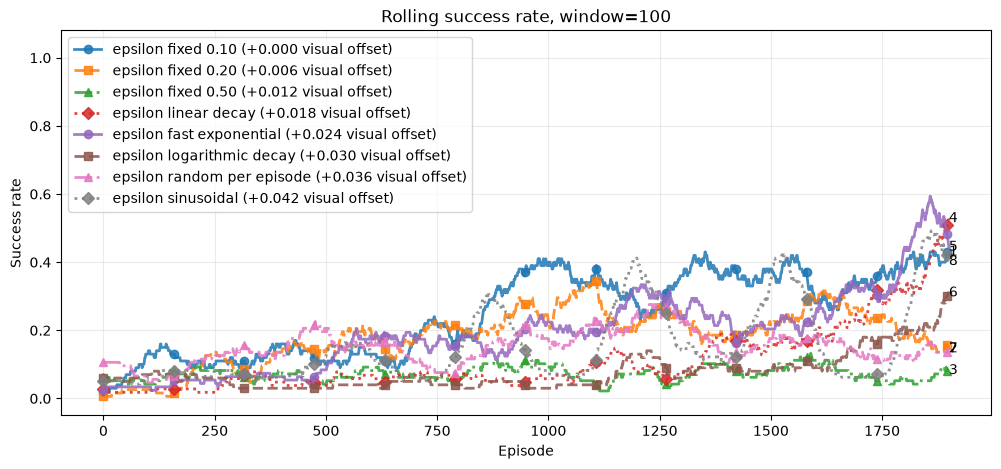

In [28]:
base = {
    "episodes": 2_000,
    "alpha": ConstantSchedule(0.10),
    "gamma": ConstantSchedule(0.95),
    "is_slippery": True,
    "reward_policy": DEFAULT_REWARD,
}

exploration_configs = [
    QLearningConfig(name="epsilon fixed 0.10", epsilon=ConstantSchedule(0.10), **base),
    QLearningConfig(name="epsilon fixed 0.20", epsilon=ConstantSchedule(0.20), **base),
    QLearningConfig(name="epsilon fixed 0.50", epsilon=ConstantSchedule(0.50), **base),
    QLearningConfig(name="epsilon linear decay", epsilon=LinearDecaySchedule(1.0, 0.05), **base),
    QLearningConfig(name="epsilon fast exponential", epsilon=ExponentialDecaySchedule(1.0, 0.05, decay_rate=0.010), **base),
    QLearningConfig(name="epsilon logarithmic decay", epsilon=LogarithmicDecaySchedule(1.0, 0.05, curve=-.90), **base),
    QLearningConfig(name="epsilon random per episode", epsilon=RandomUniformSchedule(0.05, 0.80, seed=7), **base),
    QLearningConfig(name="epsilon sinusoidal", epsilon=SinusoidalSchedule(0.05, 0.80, periods=6), **base),
]

exploration_results = run_experiments(exploration_configs, evaluation_episodes=200)
summarize_results(exploration_results)
plot_learning_curves(exploration_results, window=100)

## Experiment set 2: reward policies

Reward shaping often makes sparse environments easier, but it can also teach a behavior that optimizes the shaped reward rather than the real environment reward.

Training default reward...
Training step penalty...
Training hole penalty...
Training step + hole + goal...
experiment                          slippery   train@500       eval  eval reward
----------------------------------------------------------------------------------
default reward                      True           0.322      0.716        0.716
step penalty                        True           0.230      0.212        0.065
hole penalty                        True           0.354      0.732        0.580
step + hole + goal                  True           0.362      0.634        0.576


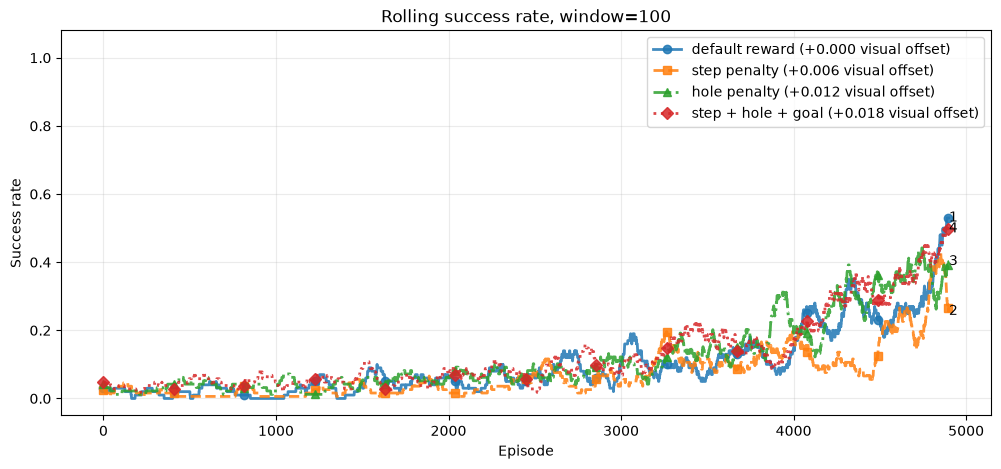

In [27]:
reward_configs = [
    QLearningConfig(name="default reward", epsilon=LinearDecaySchedule(1.0, 0.05), **base),
    QLearningConfig(name="step penalty", epsilon=LinearDecaySchedule(1.0, 0.05), reward_policy=STEP_PENALTY_REWARD, **{k: v for k, v in base.items() if k != "reward_policy"}),
    QLearningConfig(name="hole penalty", epsilon=LinearDecaySchedule(1.0, 0.05), reward_policy=HOLE_PENALTY_REWARD, **{k: v for k, v in base.items() if k != "reward_policy"}),
    QLearningConfig(name="step + hole + goal", epsilon=LinearDecaySchedule(1.0, 0.05), reward_policy=SHAPED_REWARD, **{k: v for k, v in base.items() if k != "reward_policy"}),
]

reward_results = run_experiments(reward_configs, evaluation_episodes=500)
summarize_results(reward_results)
plot_learning_curves(reward_results, window=100)

## Experiment set 3: alpha, gamma, slippery

Here you can compare deterministic vs slippery dynamics and scheduled `alpha`/`gamma`.

In [ ]:
episodes = 5_000

tuning_configs = [
    QLearningConfig(
        name="slippery stable alpha/gamma",
        episodes=episodes,
        alpha=ConstantSchedule(0.10),
        gamma=ConstantSchedule(0.95),
        epsilon=ExponentialDecaySchedule(1.0, 0.05, decay_rate=0.010),
        is_slippery=True,
    ),
    QLearningConfig(
        name="deterministic stable alpha/gamma",
        episodes=episodes,
        alpha=ConstantSchedule(0.10),
        gamma=ConstantSchedule(0.95),
        epsilon=ExponentialDecaySchedule(1.0, 0.05, decay_rate=0.010),
        is_slippery=False,
    ),
    QLearningConfig(
        name="slippery alpha decay, gamma increases",
        episodes=episodes,
        alpha=LinearDecaySchedule(0.50, 0.05),
        gamma=LinearDecaySchedule(0.70, 0.99),
        epsilon=ExponentialDecaySchedule(1.0, 0.05, decay_rate=0.010),
        is_slippery=True,
    ),
    QLearningConfig(
        name="deterministic alpha decay, gamma increases",
        episodes=episodes,
        alpha=LinearDecaySchedule(0.50, 0.05),
        gamma=LinearDecaySchedule(0.70, 0.99),
        epsilon=ExponentialDecaySchedule(1.0, 0.05, decay_rate=0.010),
        is_slippery=False,
    ),
]

tuning_results = run_experiments(tuning_configs, evaluation_episodes=500)
summarize_results(tuning_results)
diagnose_results(tuning_results)
plot_learning_curves(tuning_results, window=5)

Training slippery stable alpha/gamma...
Training deterministic stable alpha/gamma...
Training slippery alpha decay, gamma increases...


## Inspect one learned policy

deterministic stable alpha/gamma
evaluation success rate: 1.000
R  R  D  L
U  H  D  H
R  R  D  H
H  R  R  G
Legend: L=left, D=down, R=right, U=up, ?=no clear learned preference, H=hole, G=goal


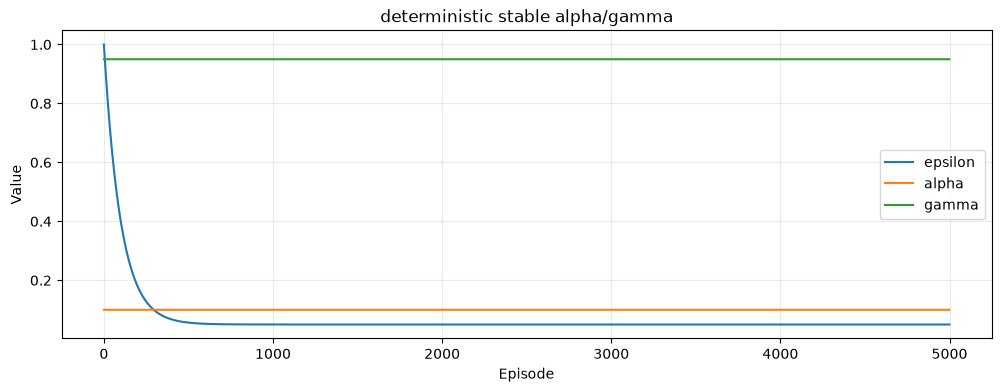

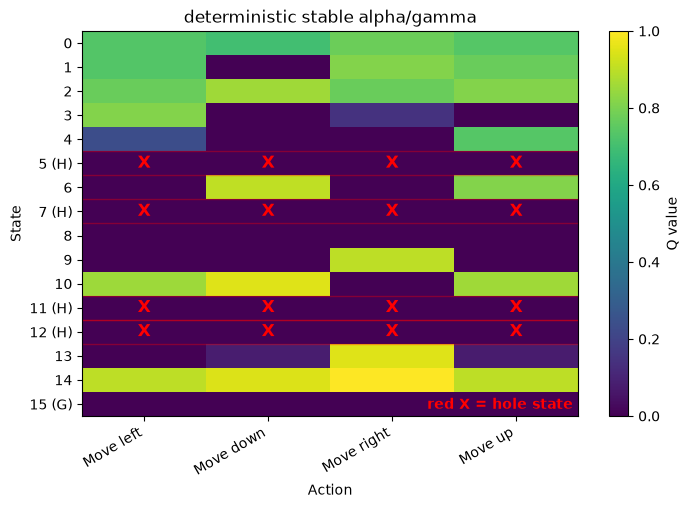

In [29]:
best_result = max(exploration_results + reward_results + tuning_results, key=lambda result: result.evaluation_success_rate)
print(best_result.config.name)
print(f"evaluation success rate: {best_result.evaluation_success_rate:.3f}")

show_policy(best_result)
plot_parameter_history(best_result)
plot_q_table(best_result)

## Your custom experiment

Change anything below and rerun only this cell.

Training my custom config...
experiment                          slippery   train@500       eval  eval reward
----------------------------------------------------------------------------------
my custom config                    True           0.414      0.627        0.769


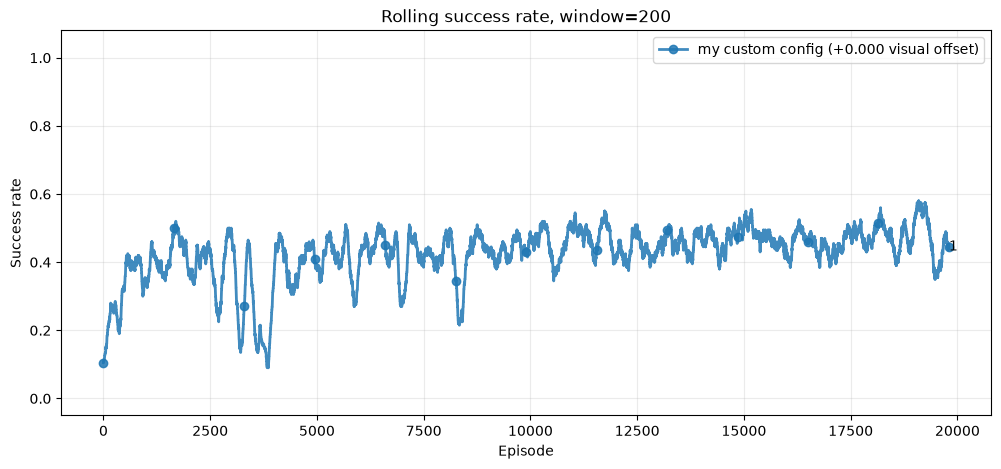

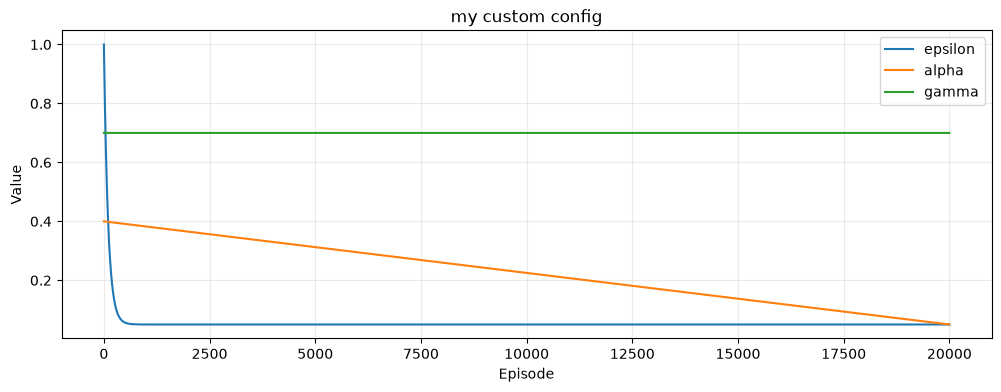

L  U  U  U
L  H  R  H
U  D  L  H
H  R  R  G
Legend: L=left, D=down, R=right, U=up, ?=no clear learned preference, H=hole, G=goal


In [30]:
custom_config = QLearningConfig(
    name="my custom config",
    episodes=20_000,
    alpha=LinearDecaySchedule(start=0.40, end=0.05),
    gamma=ConstantSchedule(0.7),
    epsilon=ExponentialDecaySchedule(start=1, end=.05, decay_rate=0.01),
    is_slippery=True,
    reward_policy=RewardPolicy(step_penalty=-0.005, hole_penalty=-1.0, goal_bonus=1.0),
    seed=123,
)

custom_result = run_experiments([custom_config], evaluation_episodes=1_000)[0]
summarize_results([custom_result])
plot_learning_curves([custom_result], window=200)
plot_parameter_history(custom_result)
show_policy(custom_result)